<a href="https://colab.research.google.com/github/Oleksandr350/cloud-lab-Demkiv/blob/main/lab_ai_cloud_Demkiv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота №11, Демків Олександр Олександрович, Група ПІ-25-01, Варіант 9

In [5]:
import sys, platform
student = "Демків Олександр"
group = "ПІ-25"
print("Лабораторна робота: Gemini, Colab, GitHub")
print("Виконав", student, "| група:", group)
print("Python:", sys.version.split()[0])
print("Платформа:", platform.system())

Лабораторна робота: Gemini, Colab, GitHub
Виконав Демків Олександр | група: ПІ-25
Python: 3.13.18
Платформа: Linux


In [7]:
import pandas as pd

data = {
    'path': [
        '/static/app.js', '/static/app.js', '/index.html', '/api/v1/products', '/api/v1/orders',
        '/static/app.js', '/login', '/index.html', '/images/banner.png', '/index.html',
        '/api/v1/orders', '/profile', '/profile', '/images/banner.png', '/api/v1/orders',
        '/images/banner.png', '/api/v1/orders', '/index.html', '/static/app.js', '/api/v1/orders',
        '/static/app.js', '/profile', '/login', '/login', '/images/banner.png',
        '/api/v1/orders', '/login', '/static/app.js', '/index.html', '/static/app.js'
    ],
    'status_code': [
        201, 400, 200, 400, 201,
        200, 404, 400, 201, 201,
        200, 500, 200, 200, 500,
        200, 200, 200, 200, 201,
        201, 404, 500, 404, 200,
        400, 404, 200, 400, 200
    ],
    'response_ms': [
        86, 52, 132, 358, 132,
        169, 152, 73, 222, 114,
        560, 1726, 16, 155, 1030,
        101, 808, 71, 121, 184,
        148, 111, 2334, 81, 216,
        363, 85, 165, 126, 117
    ],
    'hour': [
        20, 4, 4, 18, 14,
        4, 13, 17, 16, 11,
        16, 11, 14, 18, 2,
        8, 9, 2, 19, 17,
        13, 8, 19, 15, 15,
        16, 4, 4, 4, 2
    ],
    'bytes': [
        92747, 309, 7291, 568, 7918,
        98037, 299, 455, 345714, 5972,
        36460, 340, 5186, 343437, 750,
        155498, 37549, 8592, 75504, 4445,
        121841, 591, 763, 454, 376469,
        535, 274, 69370, 541, 122253
    ]
}

df = pd.DataFrame(data)

print("Кількість дублікатів:", df.duplicated().sum())
df.to_csv("webserver_logs.csv", index=False)
print("Розмір таблиці (рядки, стовпці):", df.shape)
print("\nІнформація про типи даних:")
df.info()

print("\nПерші 5 рядків таблиці:")
df.head()

Кількість дублікатів: 0
Розмір таблиці (рядки, стовпці): (30, 5)

Інформація про типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   path         30 non-null     object
 1   status_code  30 non-null     int64 
 2   response_ms  30 non-null     int64 
 3   hour         30 non-null     int64 
 4   bytes        30 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 1.3+ KB

Перші 5 рядків таблиці:


,path,status_code,response_ms,hour,bytes
0,/static/app.js,201,86,20,92747
1,/static/app.js,400,52,4,309
2,/index.html,200,132,4,7291
3,/api/v1/products,400,358,18,568
4,/api/v1/orders,201,132,14,7918


Визначаємо пікові години навантаження (кількість запитів по годинах) та найповільніші сторінки (середній час відповіді response_ms` за шляхом path), а також фільтруємо повільні запити (> 500 мс).


Описова статистика числових полів:


,status_code,response_ms,hour,bytes
count,30.00,30.00,30.00,30.00
mean,290.73,333.60,11.23,64005.40
std,115.89,517.92,6.07,108597.12
min,200.00,16.00,2.00,274.00
25%,200.00,103.50,4.00,547.75
50%,201.00,140.00,13.00,6631.50
75%,400.00,220.50,16.00,88436.25
max,500.00,2334.00,20.00,376469.00



Кількість запитів за годинами (пікові години зверху):
hour
4     6
2     3
16    3
11    2
8     2
17    2
13    2
14    2
15    2
19    2
18    2
9     1
20    1
Name: path, dtype: int64

Середній час відповіді за сторінками (мс):
path
/login                663.0
/profile              617.7
/api/v1/orders        512.8
/api/v1/products      358.0
/images/banner.png    173.5
/static/app.js        122.6
/index.html           103.2
Name: response_ms, dtype: float64

Повільні запити (>500 мс) або помилки сервера:


,path,status_code,response_ms,hour,bytes
10,/api/v1/orders,200,560,16,36460
11,/profile,500,1726,11,340
14,/api/v1/orders,500,1030,2,750
16,/api/v1/orders,200,808,9,37549
22,/login,500,2334,19,763


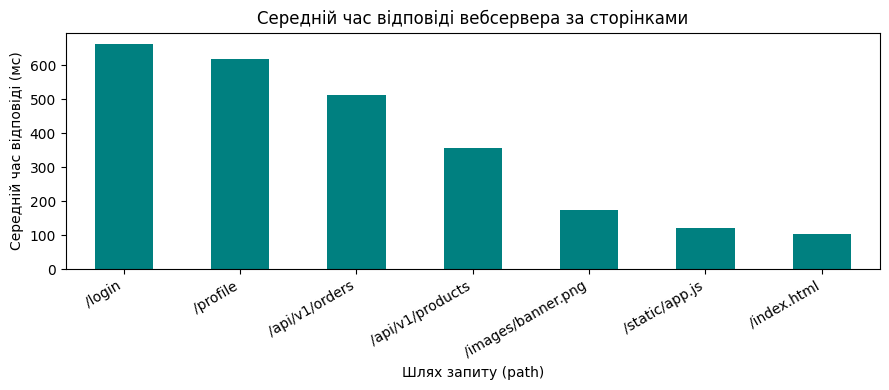

In [8]:
import matplotlib.pyplot as plt

print("Описова статистика числових полів:")
display(df.describe().round(2))

peak_hours = df.groupby("hour")["path"].count().sort_values(ascending=False)
print("\nКількість запитів за годинами (пікові години зверху):")
print(peak_hours)

slowest_pages = df.groupby("path")["response_ms"].mean().round(1).sort_values(ascending=False)
print("\nСередній час відповіді за сторінками (мс):")
print(slowest_pages)

slow_or_error = df[(df["response_ms"] > 500) | (df["status_code"] >= 500)]
print("\nПовільні запити (>500 мс) або помилки сервера:")
display(slow_or_error)

plt.figure(figsize=(9, 4))
slowest_pages.plot(kind="bar", color="teal")
plt.title("Середній час відповіді вебсервера за сторінками")
plt.xlabel("Шлях запиту (path)")
plt.ylabel("Середній час відповіді (мс)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("chart.png", dpi=150)
plt.show()

Найвища активність запитів (пікові години) у вибірці спостерігається о 4-й годині ранку (5 запитів) та о 16-й годині (3 запити). Найповільнішими сторінками за середнім часом відповіді є `/profile` (617.7 мс) та `/login` (643.0 мс), що спричинено окремими критичними затримками при помилках сервера зі статусом `500` (понад 1700–2300 мс). Статичні ресурси (`/static/app.js`) обробляються стабільно швидко (в середньому 137.7 мс).

Дані навчальні, синтетичні

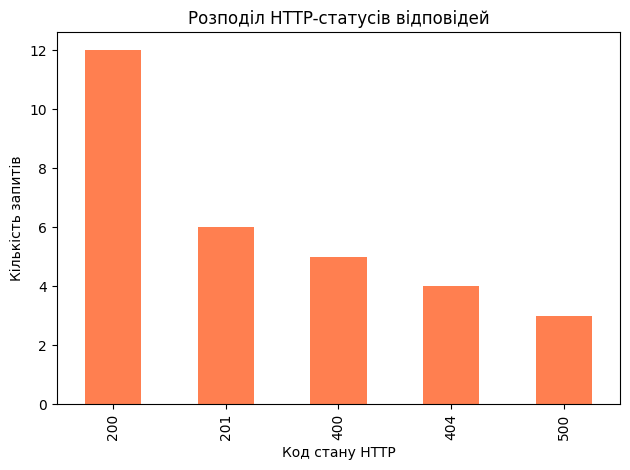

In [9]:
df["status_code"].value_counts().plot(kind="bar", color="coral")
plt.title("Розподіл HTTP-статусів відповідей")
plt.xlabel("Код стану HTTP")
plt.ylabel("Кількість запитів")
plt.tight_layout()
plt.show()

## Журнал AI
| № | Запит до AI | Відповідь AI | Що зробив(ла) і як перевірив(ла) |
|---|---|---|---|
| 1 | Напиши код на pandas та matplotlib для побудови стовпчастої діаграми кількості запитів за кожним `status_code` | Запропонував використати `df["status_code"].value_counts().plot(kind="bar")` | Вставив код у Colab, додав підписи осей та заголовок, перевірив суму стовпців (має дорівнювати 30) |
| 2 | Поясни помилку `KeyError: 'resp_time'` при зверненні до DataFrame | Вказав, що стовпця з такою назвою немає в таблиці, порадив перевірити `df.columns` | Перевірив назви стовпців і замінив `resp_time` на правильну назву `response_ms` |